# 모두몰 요약 리포트

모두몰의 고객(`customers`)·주문(`orders`)·상품(`products`) 데이터를 SQL(DuckDB)로 요약하고, 결과에서 인사이트를 정리한다.

| # | 질문 | 사용한 문법 |
|---|---|---|
| Q1 | 월별 매출 추이는? | `DATE_TRUNC` · `GROUP BY` · `COUNT` · `SUM` · `AVG` · `ORDER BY` · `LIMIT` |
| Q2 | 주문 중 정상 / 결제대기 / 이탈(취소·반품) 비율은? | `DISTINCT` · **`CASE WHEN`** · `GROUP BY` · `COUNT` · 서브쿼리 |
| Q3 | 2번 이상 구매한 재구매 고객은 누구이고, 얼마나 샀나? | `GROUP BY` · **`HAVING`** · `COUNT` · `SUM` |
| Q4 | 카테고리별 가격대는? | `GROUP BY` · `AVG` · `MIN` · `MAX` · `LIKE` |
| Q5 | 국가별 고객 수와 등급 구성은? | `GROUP BY` · **`CASE WHEN`** · `COALESCE` |

> **매출 기준**: 실제로 돈이 들어온 주문, 즉 `status`가 `Paid`(결제 완료)·`Shipped`(배송 중)인 주문만 매출로 본다.  
> `Placed`(결제 대기), `Cancelled`(취소), `Returned`(반품)는 매출에서 제외한다.

## 0. 준비

처음 한 번만 패키지를 설치한다. (이미 설치돼 있으면 건너뛰어도 된다.)

In [1]:
%pip install duckdb pandas matplotlib -q

Note: you may need to restart the kernel to use updated packages.


In [2]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

con = duckdb.connect()   # 메모리 위에 DuckDB를 연결한다.

def run(sql):
    """SQL을 실행하고 결과를 표(DataFrame)로 돌려준다."""
    return con.sql(sql).df()

### 데이터 만들기

수업 자료의 [C1]~[C4] 셀과 같은 데이터다. BigQuery와 같은 `project_name.dataset_name.표` 이름을 쓰도록 이름 공간을 만든다.

In [3]:
con.execute("""
ATTACH IF NOT EXISTS ':memory:' AS project_name;
CREATE SCHEMA IF NOT EXISTS project_name.dataset_name;
CREATE OR REPLACE TABLE project_name.dataset_name.customers (customer_id STRING, name STRING, country STRING, signup_date DATE, grade STRING);
INSERT INTO project_name.dataset_name.customers VALUES
  ('C001', '김민준', 'Korea', '2023-01-05', 'Gold'),
  ('C002', '이서연', 'Korea', '2023-02-11', 'Silver'),
  ('C003', '박도윤', 'Japan', '2023-02-20', 'Bronze'),
  ('C004', '최지우', 'USA', '2023-03-03', 'Gold'),
  ('C005', '정하준', 'Korea', '2023-03-15', 'Silver'),
  ('C006', '강서윤', 'Korea', '2023-04-01', 'Bronze'),
  ('C007', '조은우', 'Japan', '2023-04-18', 'Silver'),
  ('C008', '윤지호', 'USA', '2023-05-09', 'Gold'),
  ('C009', '임하은', 'Korea', '2023-05-22', 'Bronze'),
  ('C010', '한예준', 'Korea', '2023-06-02', 'Silver'),
  ('C011', '오시우', NULL, '2023-06-19', 'Bronze'),
  ('C012', '신아린', 'Japan', '2023-07-07', 'Silver'),
  ('C013', '권준서', 'Korea', '2023-07-25', 'Gold'),
  ('C014', '황지안', 'USA', '2023-08-10', NULL),
  ('C015', '안수아', 'Korea', '2023-08-28', 'Bronze');
CREATE OR REPLACE TABLE project_name.dataset_name.orders (order_id STRING, customer_id STRING, order_date DATE, status STRING, amount DECIMAL(12,2));
INSERT INTO project_name.dataset_name.orders VALUES
  ('O0001', 'C001', '2023-09-02', 'Paid', 125000),
  ('O0002', 'C002', '2023-09-05', 'Shipped', 89000),
  ('O0003', 'C001', '2023-09-11', 'Returned', 45000),
  ('O0004', 'C003', '2023-09-15', 'Paid', 230000),
  ('O0005', 'C004', '2023-09-20', 'Cancelled', NULL),
  ('O0006', 'C005', '2023-09-25', 'Shipped', 67000),
  ('O0007', 'C002', '2023-10-01', 'Paid', 158000),
  ('O0008', 'C006', '2023-10-04', 'Placed', 32000),
  ('O0009', 'C007', '2023-10-12', 'Shipped', 410000),
  ('O0010', 'C008', '2023-10-19', 'Paid', 99000),
  ('O0011', 'C001', '2023-10-23', 'Paid', 76000),
  ('O0012', 'C009', '2023-10-28', 'Cancelled', NULL),
  ('O0013', 'C010', '2023-11-02', 'Shipped', 142000),
  ('O0014', 'C004', '2023-11-08', 'Paid', 88000),
  ('O0015', 'C011', '2023-11-13', 'Placed', 53000),
  ('O0016', 'C012', '2023-11-19', 'Shipped', 175000),
  ('O0017', 'C002', '2023-11-24', 'Returned', 61000),
  ('O0018', 'C013', '2023-11-29', 'Paid', 320000),
  ('O0019', 'C005', '2023-12-03', 'Paid', 47000),
  ('O0020', 'C008', '2023-12-09', 'Shipped', 215000),
  ('O0021', 'C014', '2023-12-14', 'Placed', 38000),
  ('O0022', 'C001', '2023-12-20', 'Paid', 134000),
  ('O0023', 'C015', '2023-12-25', 'Shipped', 92000),
  ('O0024', 'C007', '2024-01-03', 'Paid', 268000),
  ('O0025', 'C010', '2024-01-09', 'Cancelled', NULL),
  ('O0026', 'C003', '2024-01-15', 'Paid', 119000),
  ('O0027', 'C013', '2024-01-22', 'Shipped', 405000),
  ('O0028', 'C006', '2024-01-28', 'Paid', 58000),
  ('O0029', 'C004', '2024-02-04', 'Returned', 73000),
  ('O0030', 'C012', '2024-02-11', 'Paid', 187000);
CREATE OR REPLACE TABLE project_name.dataset_name.products (product_id STRING, product_name STRING, category STRING, price DECIMAL(12,2));
INSERT INTO project_name.dataset_name.products VALUES
  ('P01', '에어러너', 'Running', 89000),
  ('P02', '클래식 스니커즈', 'Sneakers', 65000),
  ('P03', '첼시 부츠', 'Boots', 145000),
  ('P04', '여름 샌들', 'Sandals', 38000),
  ('P05', '트레일 러너', 'Running', 119000),
  ('P06', '캔버스 스니커즈', 'Sneakers', 49000),
  ('P07', '워커 부츠', 'Boots', 175000),
  ('P08', '슬리퍼 샌들', 'Sandals', 25000),
  ('P09', '양말 세트', 'Accessory', 12000),
  ('P10', '운동화 끈', 'Accessory', 5000);
""")

# 잘 들어갔는지 행 개수를 확인한다.
run("""
SELECT 'customers' AS 테이블, COUNT(*) AS 행수 FROM project_name.dataset_name.customers
UNION ALL SELECT 'orders', COUNT(*) FROM project_name.dataset_name.orders
UNION ALL SELECT 'products', COUNT(*) FROM project_name.dataset_name.products
""")

,테이블,행수
0,customers,15
1,orders,30
2,products,10


## Q1. 월별 매출 추이는?

주문일을 월 단위로 묶어(`date_trunc`) 매출 주문(Paid·Shipped)의 건수와 매출 합계를 구한다.

In [4]:
q1 = run("""
SELECT
  date_trunc('month', order_date) AS month,
  COUNT(*)                        AS orders,
  SUM(amount)                     AS revenue,
  ROUND(AVG(amount))              AS avg_order_value   -- 객단가는 주문 1건당 평균 금액이다.
FROM project_name.dataset_name.orders
WHERE
  status IN ('Paid', 'Shipped')     -- 실제 매출 주문만 남긴다.
GROUP BY
  month
ORDER BY
  month                             -- 시간 순서대로 봐야 추이가 보인다.
""")
q1

,month,orders,revenue,avg_order_value
0,2023-09-01,4,511000.0,127750.0
1,2023-10-01,4,743000.0,185750.0
2,2023-11-01,4,725000.0,181250.0
3,2023-12-01,4,488000.0,122000.0
4,2024-01-01,4,850000.0,212500.0
5,2024-02-01,1,187000.0,187000.0


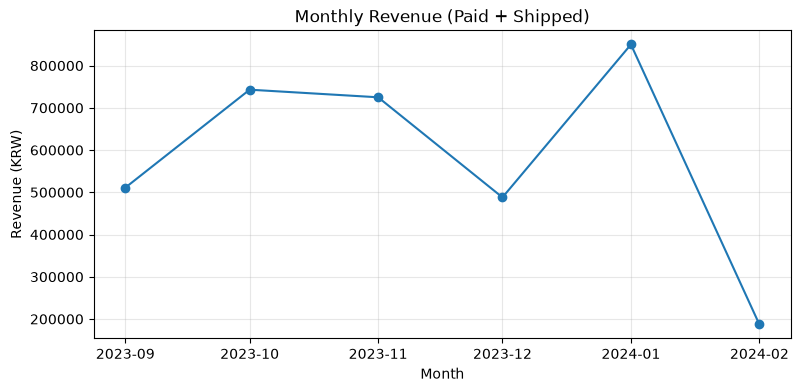

In [5]:
plt.figure(figsize=(9, 4))
plt.plot(q1['month'], q1['revenue'], marker='o')
plt.title('Monthly Revenue (Paid + Shipped)')
plt.xlabel('Month')
plt.ylabel('Revenue (KRW)')
plt.grid(True, alpha=0.3)
plt.show()

매출이 가장 높았던 달 TOP 3를 뽑아 본다. 매출 큰 순으로 정렬(`DESC`)한 뒤 위에서 3개만 자른다(`LIMIT`).

In [6]:
run("""
SELECT
  date_trunc('month', order_date) AS month,
  SUM(amount)                     AS revenue
FROM project_name.dataset_name.orders
WHERE
  status IN ('Paid', 'Shipped')
GROUP BY
  month
ORDER BY
  revenue DESC                      -- 매출이 큰 달부터 정렬한다.
LIMIT 3                             -- 상위 3개만 남긴다.
""")

,month,revenue
0,2024-01-01,850000.0
1,2023-10-01,743000.0
2,2023-11-01,725000.0


**💡 인사이트**: 월 주문 건수는 매달 4건으로 같은데 매출은 48.8만~85만 원으로 크게 출렁인다. 매출 차이는 **주문 수가 아니라 객단가(고액 주문 여부)** 에서 나온다. (2024년 2월은 11일까지만 데이터가 있어 비교에서 제외했다.)

## Q2. 주문 중 정상 / 결제대기 / 이탈(취소·반품) 비율은?

먼저 `DISTINCT`로 주문 상태에 어떤 값들이 있는지 확인한다.

In [7]:
run("""
SELECT DISTINCT
  status
FROM project_name.dataset_name.orders
ORDER BY
  status
""")

,status
0,Cancelled
1,Paid
2,Placed
3,Returned
4,Shipped


상태 값은 5가지다. `CASE WHEN`으로 이를 3개 그룹으로 묶고, 그룹별 건수와 전체 대비 비율을 구한다.  
비율의 분모(전체 주문 수)는 서브쿼리로 구한다.

In [8]:
q2 = run("""
SELECT
  CASE
    WHEN status IN ('Paid', 'Shipped')       THEN '정상'
    WHEN status = 'Placed'                   THEN '결제대기'
    WHEN status IN ('Cancelled', 'Returned') THEN '이탈(취소·반품)'
  END                                          AS order_group,
  COUNT(*)                                     AS orders,
  ROUND(COUNT(*) * 100.0
        / (SELECT COUNT(*) FROM project_name.dataset_name.orders), 1) AS pct
FROM project_name.dataset_name.orders
GROUP BY
  order_group
ORDER BY
  orders DESC                       -- 많은 그룹부터 정렬한다.
""")
q2

,order_group,orders,pct
0,정상,21,70.0
1,이탈(취소·반품),6,20.0
2,결제대기,3,10.0


**💡 인사이트**: 전체 30건 중 6건(20%)이 취소·반품으로 이탈했다. **주문 5건 중 1건이 매출로 이어지지 못하므로**, 취소·반품 사유를 확인해 줄이는 것이 매출을 늘리는 쉬운 방법이다.

## Q3. 2번 이상 구매한 재구매 고객은 누구이고, 얼마나 샀나?

고객별로 매출 주문을 묶은 뒤, **`HAVING`** 으로 "주문 2건 이상"인 그룹만 남긴다.  
(`WHERE`는 묶기 전의 행을 거르고, `HAVING`은 묶은 뒤의 그룹을 거른다.)

In [9]:
q3 = run("""
SELECT
  customer_id,
  COUNT(*)    AS orders,
  SUM(amount) AS total_amount
FROM project_name.dataset_name.orders
WHERE
  status IN ('Paid', 'Shipped')
GROUP BY
  customer_id
HAVING
  COUNT(*) >= 2                     -- 재구매 고객만 남긴다.
ORDER BY
  total_amount DESC                 -- 많이 산 고객부터 정렬한다.
""")
q3

,customer_id,orders,total_amount
0,C013,2,725000.0
1,C007,2,678000.0
2,C012,2,362000.0
3,C003,2,349000.0
4,C001,3,335000.0
5,C008,2,314000.0
6,C002,2,247000.0
7,C005,2,114000.0


In [10]:
# 비교용으로 매출 주문이 있는 전체 고객 수와 전체 매출을 구한다.
total = run("""
SELECT
  COUNT(DISTINCT customer_id) AS buyers,
  SUM(amount)                 AS total_revenue
FROM project_name.dataset_name.orders
WHERE
  status IN ('Paid', 'Shipped')
""")
print('재구매 고객 수:', len(q3), '/ 구매 고객 수:', total['buyers'][0])
print('재구매 고객 매출 비중:', round(q3['total_amount'].sum() / total['total_revenue'][0] * 100, 1), '%')

재구매 고객 수: 8 / 구매 고객 수: 12
재구매 고객 매출 비중: 89.2 %


**💡 인사이트**: 구매 고객 12명 중 8명이 재구매 고객이고, 이들이 **전체 매출의 약 89%** 를 만든다. 신규 유치보다 기존 고객을 붙잡는 것(재구매 혜택 등)이 매출에 더 중요하다.

## Q4. 카테고리별 가격대는?

상품을 카테고리별로 묶어 평균·최저·최고 가격을 구하고, 평균 가격이 높은 순으로 정렬한다.

In [11]:
q4 = run("""
SELECT
  category,
  COUNT(*)            AS products,
  ROUND(AVG(price))   AS avg_price,
  MIN(price)          AS min_price,
  MAX(price)          AS max_price
FROM project_name.dataset_name.products
GROUP BY
  category
ORDER BY
  avg_price DESC                    -- 비싼 카테고리부터 정렬한다.
""")
q4

,category,products,avg_price,min_price,max_price
0,Boots,2,160000.0,145000.0,175000.0
1,Running,2,104000.0,89000.0,119000.0
2,Sneakers,2,57000.0,49000.0,65000.0
3,Sandals,2,31500.0,25000.0,38000.0
4,Accessory,2,8500.0,5000.0,12000.0


가장 비싼 카테고리인 부츠 상품을 상품명으로 찾아 본다. `LIKE '%부츠%'`는 이름 어딘가에 '부츠'가 들어간 상품을 찾는다.

In [12]:
run("""
SELECT
  product_name,
  category,
  price
FROM project_name.dataset_name.products
WHERE
  product_name LIKE '%부츠%'        -- 이름에 '부츠'가 들어간 상품을 찾는다.
ORDER BY
  price DESC
""")

,product_name,category,price
0,워커 부츠,Boots,175000.0
1,첼시 부츠,Boots,145000.0


**💡 인사이트**: Boots 평균가(16만 원)가 Accessory(8,500원)의 약 19배다. Boots·Running은 **객단가를 끌어올리는 주력 상품**, Accessory는 다른 상품과 함께 사는 **추가 구매용**으로 활용할 수 있다. (주문 데이터에 상품 정보가 없어 카테고리별 실제 판매량은 확인할 수 없다.)

## Q5. 국가별 고객 수와 등급 구성은?

국가별로 고객을 묶고, `CASE WHEN`으로 등급별 인원을 각각 센다.  
조건에 맞으면 1, 아니면 NULL이 되고 `COUNT`는 NULL을 세지 않으므로 조건에 맞는 사람 수만 나온다.  
국가가 비어 있는(NULL) 고객은 `COALESCE`로 '미입력'으로 표시한다.

In [13]:
q5 = run("""
SELECT
  COALESCE(country, '미입력')                         AS country,
  COUNT(*)                                            AS customers,
  COUNT(CASE WHEN grade = 'Gold'   THEN 1 END)        AS gold,
  COUNT(CASE WHEN grade = 'Silver' THEN 1 END)        AS silver,
  COUNT(CASE WHEN grade = 'Bronze' THEN 1 END)        AS bronze,
  COUNT(CASE WHEN grade IS NULL    THEN 1 END)        AS no_grade
FROM project_name.dataset_name.customers
GROUP BY
  country
ORDER BY
  customers DESC,                   -- 고객이 많은 나라부터 정렬한다.
  gold DESC                         -- 같으면 Gold가 많은 나라를 먼저 둔다.
""")
q5

,country,customers,gold,silver,bronze,no_grade
0,Korea,8,2,3,3,0
1,USA,3,2,0,0,1
2,Japan,3,0,2,1,0
3,미입력,1,0,0,1,0


**💡 인사이트**: 고객 15명 중 8명(53%)이 한국 고객이다. 미국은 고객 3명 중 **등급이 있는 2명이 모두 Gold**라 인원 대비 우수 고객 비중이 가장 높고, 일본은 Gold가 없다. 국가·등급이 비어 있는 고객도 1명씩 있어 데이터 입력 보완이 필요하다.

## 요약

| 질문 | 한 줄 인사이트 |
|---|---|
| Q1 월별 매출 | 매달 주문이 4건으로 같아도 매출이 크게 달라서, 매출은 객단가가 좌우한다. |
| Q2 주문 상태 | 주문 5건 중 1건(20%)이 취소·반품으로 이탈한다. |
| Q3 재구매 고객 | 재구매 고객 8명이 매출의 약 89%를 차지한다. |
| Q4 카테고리 가격 | Boots 평균가가 Accessory의 약 19배라서 주력 상품과 추가 구매용 상품으로 역할을 나눌 수 있다. |
| Q5 국가·등급 | 고객 절반 이상이 한국이고, 미국은 Gold 비중이 높다. |

## 부록. 오늘의 쿼리 패턴 치트시트

| 하고 싶은 것 | SQL | 이 리포트에서 쓴 곳 |
|---|---|---|
| 정렬 (내림차순) | `ORDER BY 열 DESC` | Q2 · Q3 · Q4 · Q5 |
| 상위 N개 | `ORDER BY ... LIMIT N` | Q1 매출 TOP 3 달 |
| 중복 제거 | `SELECT DISTINCT 열` | Q2 상태 값 확인, Q3 `COUNT(DISTINCT customer_id)` |
| 이름표 붙이기 | `열 AS 별칭` | 모든 질문 (`revenue`, `orders` 등) |
| 패턴 검색 | `WHERE 열 LIKE '%키워드%'` | Q4 부츠 상품 찾기 |
| 조건 분류 | `CASE WHEN 조건 THEN 값 ELSE 값 END` | Q2 주문 그룹, Q5 등급별 인원 |
| 요약 | `COUNT(*)`, `SUM`, `AVG`, `MAX`, `MIN` | Q1 · Q2 · Q3 · Q4 · Q5 |
| 그룹별 요약 | `GROUP BY 그룹열` | Q1 · Q2 · Q3 · Q4 · Q5 |
| 그룹 거르기 | `HAVING 집계조건` | Q3 재구매 고객 (`COUNT(*) >= 2`) |